# Sales Prediction with Machine Learning

## Proje Amacı
İlk Önce Projeyi bu adresten aldım : https://thecleverprogrammer.com/2021/05/19/sales-prediction-with-machine-learning/


Genellikle, ürün ve hizmet tabanlı bir işletme, ürünlerinin reklam maliyetini manipüle etmek için attıkları her adımda gelecekteki satışlarını tahmin etmek için Veri Bilimcisine her zaman ihtiyaç duyar. O halde satış tahmini görevine Python kullanarak makine öğrenimiyle başlayalım. Bu göreve gerekli Python kütüphanelerini ve veri setini içe aktararak başlayacağım:

### importing

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

In [5]:
df = pd.read_csv("https://raw.githubusercontent.com/amankharwal/Website-data/master/advertising.csv")
print(df.head())

      TV  Radio  Newspaper  Sales
0  230.1   37.8       69.2   22.1
1   44.5   39.3       45.1   10.4
2   17.2   45.9       69.3   12.0
3  151.5   41.3       58.5   16.5
4  180.8   10.8       58.4   17.9


## EDA - Exploratory Data Analysis

In [7]:
df.shape

(200, 4)

In [8]:
df.sample()

,TV,Radio,Newspaper,Sales
186,139.5,2.1,26.6,10.3


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB


In [10]:
df.describe()

,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,15.130500
std,85.854236,14.846809,21.778621,5.283892
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,11.000000
50%,149.750000,22.900000,25.750000,16.000000
75%,218.825000,36.525000,45.100000,19.050000
max,296.400000,49.600000,114.000000,27.000000


In [11]:
df.corr(numeric_only=True)  # corelasyon hesaplıyor

,TV,Radio,Newspaper,Sales
TV,1.000000,0.054809,0.056648,0.901208
Radio,0.054809,1.000000,0.354104,0.349631
Newspaper,0.056648,0.354104,1.000000,0.157960
Sales,0.901208,0.349631,0.157960,1.000000


In [12]:
import seaborn as sns

In [13]:
df.isnull().sum() # hangi sütunda boş veri var

TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

In [14]:
df['Sales'].value_counts()

Sales
16.7    5
11.9    5
20.7    4
17.3    3
11.3    3
       ..
24.2    1
8.1     1
5.5     1
23.7    1
6.9     1
Name: count, Length: 121, dtype: int64

In [15]:
df['Sales'].value_counts(normalize=True) # bu veri içinde yüzdeleri görmek için

Sales
16.7    0.025
11.9    0.025
20.7    0.020
17.3    0.015
11.3    0.015
        ...  
24.2    0.005
8.1     0.005
5.5     0.005
23.7    0.005
6.9     0.005
Name: proportion, Length: 121, dtype: float64

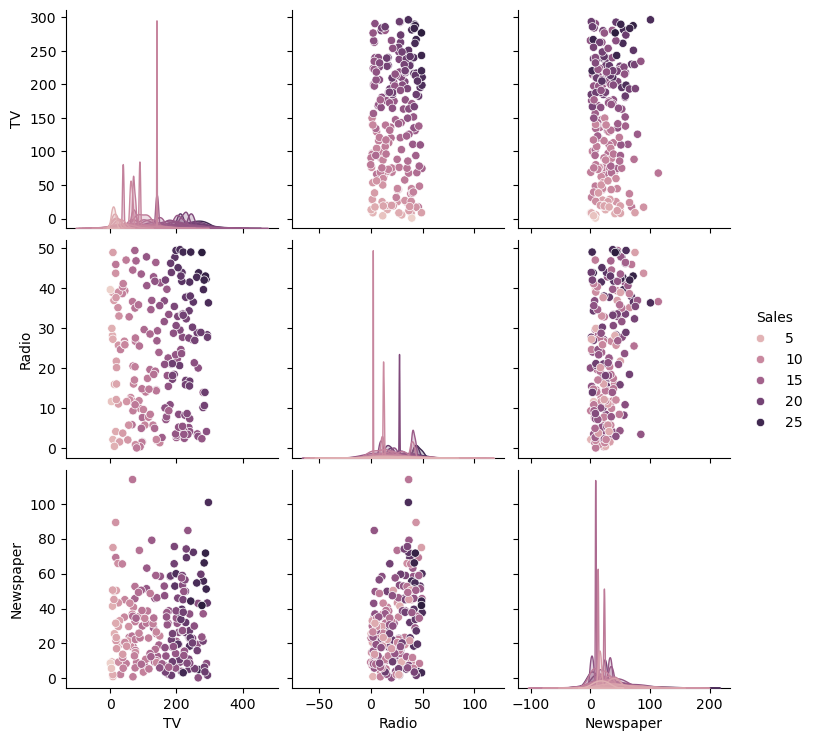

In [16]:
sns.pairplot(df,hue='Sales') # bütün sütunların bütün sütunlara göre değişimi marka rengi farklı

In [17]:
df.corr(numeric_only=True)  # corelasyon hesaplıyor

,TV,Radio,Newspaper,Sales
TV,1.000000,0.054809,0.056648,0.901208
Radio,0.054809,1.000000,0.354104,0.349631
Newspaper,0.056648,0.354104,1.000000,0.157960
Sales,0.901208,0.349631,0.157960,1.000000


In [18]:
abs(df.corr(numeric_only=True)['Sales'].sort_values(ascending=False))

Sales        1.000000
TV           0.901208
Radio        0.349631
Newspaper    0.157960
Name: Sales, dtype: float64

### Modelling

In [20]:
df.isnull().sum()

TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

In [21]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB


In [22]:
#pip install --upgrade scikit-learn

In [23]:
x = np.array(df.drop(["Sales"], axis=1))
y = np.array(df["Sales"])

from sklearn.model_selection import train_test_split
xtrain, xtest, ytrain, ytest = train_test_split(x, y, test_size=0.2, random_state=42)

In [24]:
model = LinearRegression()
model.fit(xtrain, ytrain)
ypred=model.predict(xtest)

In [28]:
import pickle
from sklearn.linear_model import LinearRegression

# Modelinizi oluşturun
model = LinearRegression()

# Modeli eğitin (örnek veri ile)
# model.fit(X_train, y_train)

# Modeli kaydet
with open('model.pkl', 'wb') as file:
    pickle.dump(model, file)

In [30]:
data = pd.DataFrame(data={"Tahmini Satış rakamları": ypred.flatten()})

In [32]:
data

,Tahmini Satış rakamları
0,17.034772
1,20.409740
2,23.723989
3,9.272785
4,21.682719
5,12.569402
6,21.081195
7,8.690350
8,17.237013
9,16.666575


Makine öğrenmesi ile gelecekteki satış rakamlarını bu şekilde tahmin edebiliriz.